**Why Business Leaders Don't Buy "Black Boxes"**

- The Accuracy of your model does not impress stakeholders

- A 95% model accuracy is worthless to a business stakeholder if they cannot understand why it makes such decisions.

- They don't trust it; it lacks clarity; it lacks actionable business insights

- Data Visualization acts as the translation layer across the entire ML pipeline

**Business-Valued ML Visualization**

- Phase 1: Risk & Data Quality: There is a business problem of corrupted, heavily skewed, and incomplete data.

- Solution: Visualize the errors, extreme outliers, missing information...

- Phase 2: ROI & Lever Discoveries: There is a business problem of investing in factors that won't impact their goals & preferred outcomes

- Solution: Visualizing how spending directly impacts their Return On Investment.

- Phase 3: Model Auditing & Trust: Business problem is knowing the cost of the model's mistakes.

- Solution: Visualizing model errors in simple business terms

**Real-World Scenario: You are advising the State Department of Education. They need to allocate $50 Million intervention fund to imporove student performance(Math Proficiency)**

**Step 1: Setup Environment & Data Ingestion**

In [13]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Clean & Professional Visual Aesthetics
plt.style.use('seaborn-v0_8-whitegrid')
sns.set_palette("muted")

# Ingest our US Education System Dataset (supports local repo & Google Colab)
data_path = "us_education_system_dataset.csv" if os.path.exists("us_education_system_dataset.csv") else "/content/drive/MyDrive/Data/us_education_system_dataset.csv"
us_edu_data = pd.read_csv(data_path)

In [14]:
#plt.style.available

In [15]:
allocation_data = us_edu_data[['institution_name', 'level', 'control',
             'title_i_status', 'per_pupil_expenditure_usd',
             'percent_free_reduced_lunch', 'math_proficiency_pct']]

In [16]:
allocation_data.head()

,institution_name,level,control,title_i_status,per_pupil_expenditure_usd,percent_free_reduced_lunch,math_proficiency_pct
0,Jefferson Elementary School,Elementary School,Public,Title I Schoolwide,12840,48.9,58.3
1,Lakeshore Middle School,Middle School,Private Religious,Not Applicable,17009,1.2,84.8
2,Meadowbrook Elementary Academy,Elementary School,Private For-Profit,Not Applicable,15374,36.0,54.6
3,Roosevelt Primary School,Elementary School,Public,Not Title I Eligible,17065,15.1,66.1
4,Highland Park Primary School,Elementary School,Public,Title I Targeted,16823,45.6,54.6


**Step 2: Resource Allocation Audit**

- Business Insight: Leadership must understand how funds are currently distributed across institutions.

- Are funds evenly spread, or concentrated in specific school types?

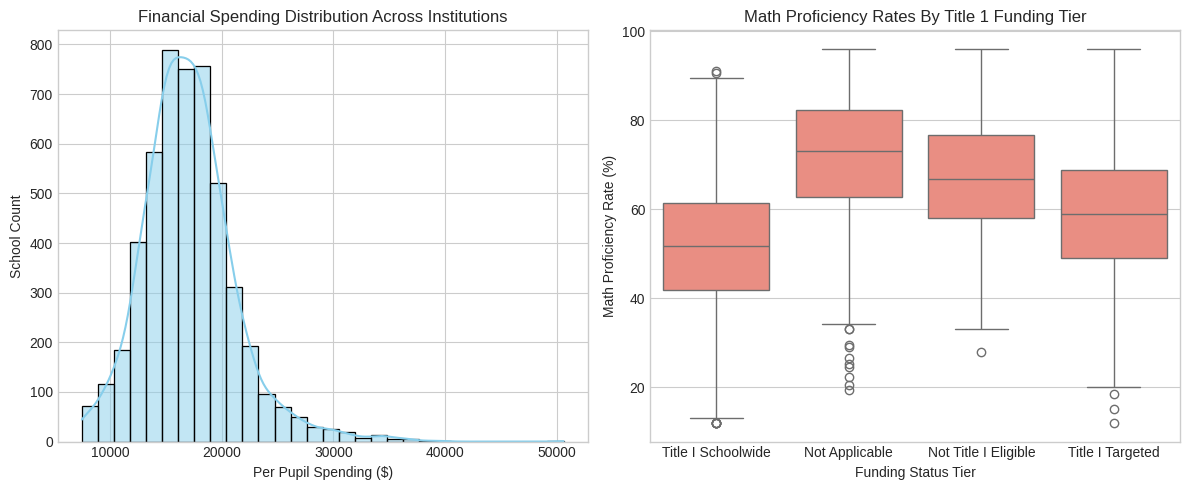

In [17]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

# Plot 1: Show financial distribution skewness
sns.histplot(allocation_data['per_pupil_expenditure_usd'], kde=True,
             ax=axes[0], color='skyblue', bins=30)
axes[0].set_title('Financial Spending Distribution Across Institutions')
axes[0].set_xlabel('Per Pupil Spending ($)')
axes[0].set_ylabel('School Count')

# Plot 2: Performance Across Funding Eligibility
sns.boxplot(data=allocation_data, x='title_i_status', y='math_proficiency_pct',
            ax=axes[1], color='salmon')
axes[1].set_title('Math Proficiency Rates By Title 1 Funding Tier')
axes[1].set_xlabel('Funding Status Tier')
axes[1].set_ylabel('Math Proficiency Rate (%)')
plt.tight_layout()
plt.show()

**Step 3: Discovering Business Levers**

- Socioeconomic Needs vs. Academic Returns

*Business Insight: "Does throwing money at schools solve performance gaps, or are socioeconomic factors stronger drivers?"*

Create a multilayered visual mapping socioeconomic needs, funding levels, school types, and math outcomes

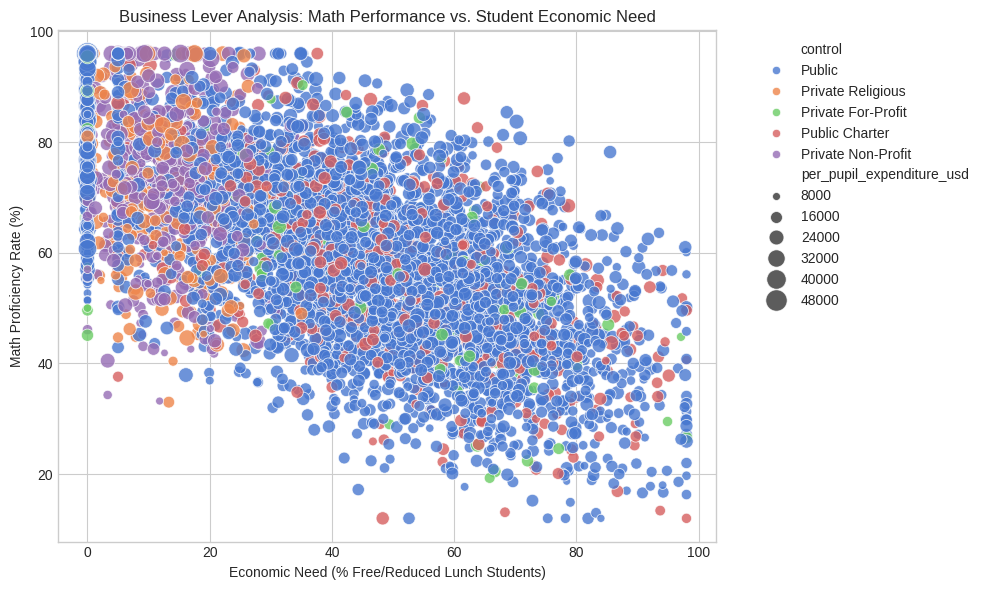

In [23]:
# Control: Institutional governance structure and funding mechanism.
plt.figure(figsize=(10, 6))

sns.scatterplot(data=allocation_data,
                x='percent_free_reduced_lunch',
                y='math_proficiency_pct',
                hue='control',
                size='per_pupil_expenditure_usd',
                sizes=(30, 250),
                alpha=0.8)

plt.title('Business Lever Analysis: Math Performance vs. Student Economic Need')
plt.xlabel('Economic Need (% Free/Reduced Lunch Students)')
plt.ylabel('Math Proficiency Rate (%)')
plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left')
plt.tight_layout()
plt.show()

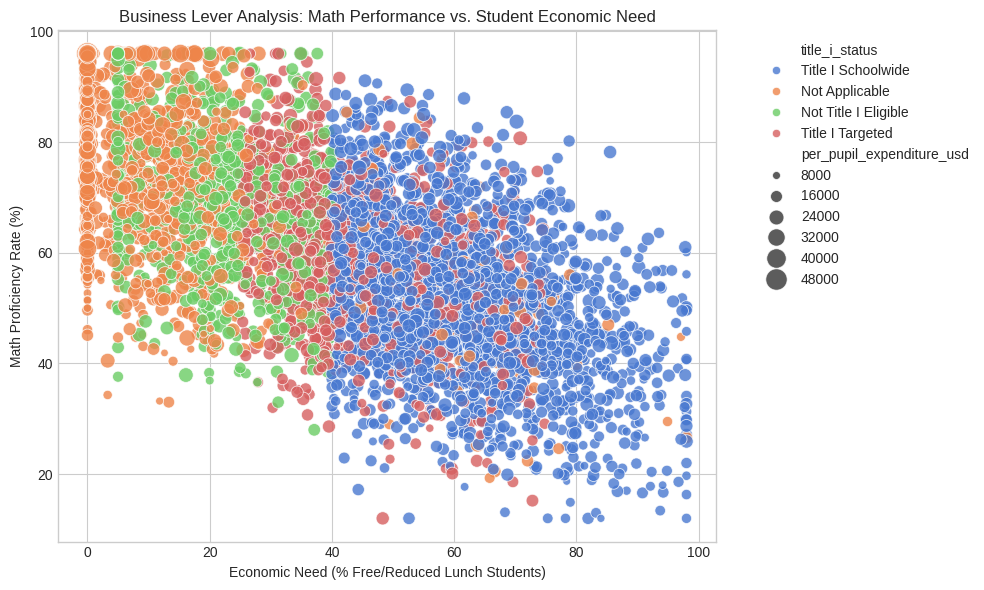

In [21]:
# Title Status: Federal Title I eligibility under ESEA for schools with high concentrations of low-income students.
plt.figure(figsize=(10, 6))

sns.scatterplot(data=allocation_data,
                x='percent_free_reduced_lunch',
                y='math_proficiency_pct',
                hue='title_i_status',
                size='per_pupil_expenditure_usd',
                sizes=(30, 250),
                alpha=0.8)

plt.title('Business Lever Analysis: Math Performance vs. Student Economic Need')
plt.xlabel('Economic Need (% Free/Reduced Lunch Students)')
plt.ylabel('Math Proficiency Rate (%)')
plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left')
plt.tight_layout()
plt.show()

**Step 4: Eliminating Redundant Features**

*Business Insight: Removing features that may confuse our model*

In [24]:
us_edu_data.columns


Index(['institution_id', 'institution_name', 'state_code', 'state_name',
       'county', 'nces_locale', 'level', 'control', 'title_i_status',
       'total_enrollment', 'number_of_teachers', 'student_teacher_ratio',
       'percent_free_reduced_lunch', 'racial_white_pct', 'racial_black_pct',
       'racial_hispanic_pct', 'racial_asian_pct', 'racial_native_pct',
       'racial_two_or_more_pct', 'special_education_pct',
       'english_learner_pct', 'per_pupil_expenditure_usd',
       'federal_funding_pct', 'state_funding_pct', 'local_funding_pct',
       'math_proficiency_pct', 'reading_proficiency_pct',
       'graduation_rate_pct', 'chronic_absenteeism_pct', 'avg_sat_score',
       'avg_act_score', 'ap_ib_participation_pct',
       'postsecondary_enrollment_pct', 'stem_certified_flag',
       'broadband_access_pct'],
      dtype='object')

In [28]:
# Key Indicators
key_indicators = ['per_pupil_expenditure_usd', 'student_teacher_ratio',
 'percent_free_reduced_lunch', 'special_education_pct',
 'english_learner_pct', 'math_proficiency_pct', 'reading_proficiency_pct',
 'graduation_rate_pct', 'broadband_access_pct']

In [29]:
key_indicators

['per_pupil_expenditure_usd',
 'student_teacher_ratio',
 'percent_free_reduced_lunch',
 'special_education_pct',
 'english_learner_pct',
 'math_proficiency_pct',
 'reading_proficiency_pct',
 'graduation_rate_pct',
 'broadband_access_pct']

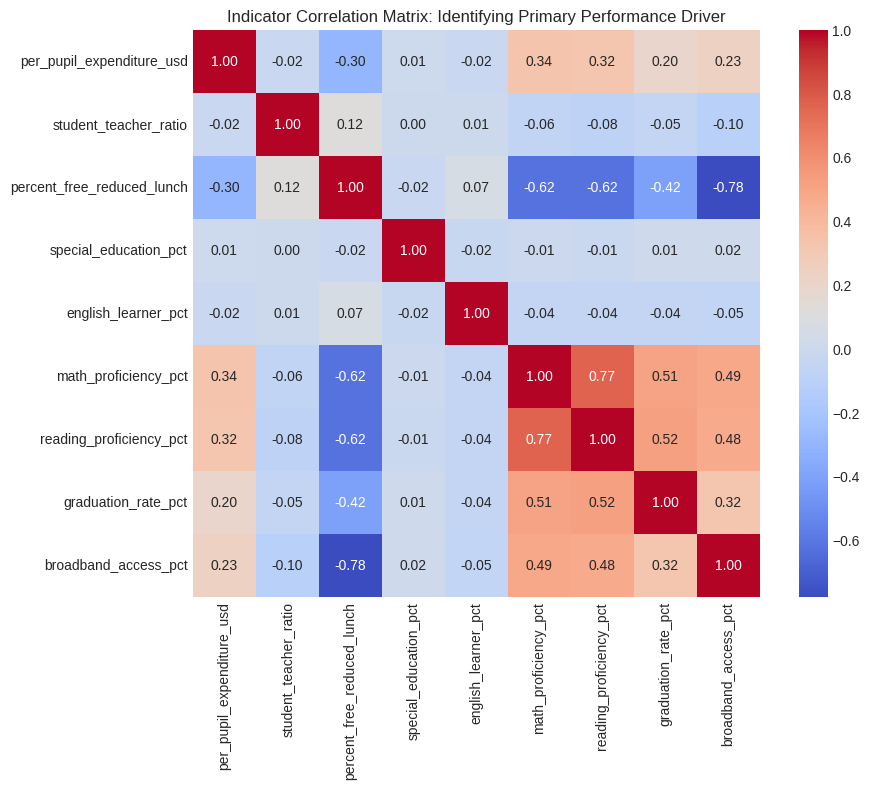

In [30]:
# Correlation Heatmap - Check Correlation Coefficients(-1 to +1)
plt.figure(figsize=(10, 8))

# Calculate Our Correlation Matrix
corr = us_edu_data[key_indicators].corr()

# Clean Visual Heatmap
sns.heatmap(corr, annot=True,
            fmt=".2f", cmap='coolwarm',
            square=True, cbar=True)
plt.title('Indicator Correlation Matrix: Identifying Primary Performance Driver')
plt.tight_layout()
plt.show()

---
## 📊 Executive Synthesis: Step 3 (Business Levers) & Step 4 (Collinearity & Feature Selection)

### 1. Step 3 Interpretation: Discovering Business Levers (Socioeconomic Needs vs. Academic Returns)
- **By Institutional Governance (`control`):** Across all 5 governance structures (`Public`, `Public Charter`, `Private Religious`, `Private For-Profit`, and `Private Non-Profit`), math proficiency declines at virtually the same slope as `percent_free_reduced_lunch` increases from `0%` to `98%`. Governance conversion alone does not immunize schools against concentrated poverty.
- **By Federal Title I Tier (`title_i_status`):** The 4D bubble plot clearly demarcates statutory policy cliffs along the X-axis: `Not Applicable` (`0%` FRPL) and `Not Title I Eligible` (`0%–25%` FRPL) occupy the high-performing upper-left (`55%–96%` math proficiency); `Title I Targeted` bridges the `20%–40%` transition zone; and `Title I Schoolwide` (`≥ 40%` FRPL) spans the entire high-need right half (`40%–98%` FRPL).
- **The Capital Cushioning Effect ("Beat-the-Odds" Schools):** Within the `Title I Schoolwide` cohort, institutions with larger expenditure bubbles (`per_pupil_expenditure_usd` ≥ `\$24,000–\$48,000`) consistently sit along the upper edge of their poverty band (`60%–85%` math proficiency), proving that targeted, needs-weighted capital investment cushions the academic impact of poverty.

### 2. Step 4 Interpretation: Eliminating Redundant Features & Auditing Collinearity
| Collinear Feature Pair | Pearson $r$ | Shared Variance ($R^2$) | Diagnostic & Modeling Action |
| :--- | :---: | :---: | :--- |
| `percent_free_reduced_lunch` ↔ `broadband_access_pct` | **`-0.78`** | **60.8%** | **Severe Negative Collinearity (Socio-Digital Divide):** Avoid pairing both in unregularized linear models ($VIF \approx 2.55$); bundle digital connectivity grants directly with Title I Schoolwide funding. |
| `math_proficiency_pct` ↔ `reading_proficiency_pct` | **`+0.77`** | **59.3%** | **Severe Positive Collinearity (Co-Moving Outcomes):** Do not use Reading to predict Math; combine into a composite proficiency index or select one when predicting `graduation_rate_pct`. |
| `percent_free_reduced_lunch` ↔ `math_proficiency_pct` / `reading_proficiency_pct` | **`-0.62`** | **38.4%** | **Primary Performance Driver:** Student economic need is the single strongest negative driver of both numeracy and literacy. |
| `reading_proficiency_pct` / `math_proficiency_pct` ↔ `graduation_rate_pct` | **`+0.52` / `+0.51`** | **27.0% / 26.0%** | **Core Academic Funnel:** Early literacy and numeracy directly drive high school completion. |
| `per_pupil_expenditure_usd` ↔ `math_proficiency_pct` / `reading_proficiency_pct` | **`+0.34` / `+0.32`** | **11.6% / 10.2%** | **Actionable Financial Lever:** Positive returns to per-pupil spending, currently diluted by regressive funding (`r = -0.30` with FRPL). |
| `student_teacher_ratio` ↔ Academic Outcomes | **`-0.05` to `-0.08`** | **< 0.7%** | **Low-ROI Policy Lever:** Near-zero linear impact; prevents leadership from wasting the \$50M fund on blanket class-size reductions. |
| `special_education_pct` & `english_learner_pct` ↔ All Features | **`-0.05` to `+0.07`** | **< 0.5%** | **Orthogonal Demographic Indicators:** Statistically independent of school-wide proficiency decline. |